- **I ('T_dim', 'X_dim', 'Color_dim') (1200, 1181, 3)**:    8-bit image color values of the timestack. Three dimensions: time, spatial axis, color band, where the colors are RGB (R=0, G=1, B=2). The horizontal axis of the image is the spatial axis. The different crs mappings represent the same coordinates in UTM, local, and longitude/latitude.
- **crs_utm () ()**:  Coordinate reference system definition for UTM coordinates.
- **crs_latlon () ()**:    Coordinate reference system definition for longitude/latitude coordinates.
- **Ri ('T_dim',) (1200,)**:    Pixel coordinate of wave runup line as found by the SegFormer model.
- **runup_val () ()**:    Runup value used to extract runup from softmax score.
- **rundown_val () ()**:    Rundown value used to extract rundown from softmax score.
- **U_transect ('X_dim',) (1181,)**:    Pixel coordinate along the horizontal axis of the image where the timestack was sampled.
- **V_transect ('X_dim',) (1181,)**:    Pixel coordinate along the vertical axis of the image where the timestack was sampled.
- **T ('T_dim',) (1200,)**:    Times that pixels were sampled to create the timestack. Format: YYYY-MM-DD HH:mm:SS+00:00. The dimension length equals the number of samples in the timestack.
- **eastings_transect ('X_dim',) (1181,)**:    Easting coordinates of timestack pixels projected onto the beach surface, described in UTM Easting meters.
- **northings_transect ('X_dim',) (1181,)**:    Northing coordinates of timestack pixels projected onto the beach surface, described in UTM Northing meters.
- **elevation_transect ('X_dim',) (1181,)**:    Elevation (z-value) of timestack pixels projected onto the beach surface.
- **localX_transect ('X_dim',) (1181,)**:    Local cross-shore coordinates in meters of the rectified image. Rotated based on shore-normal angle and origin.
- **localY_transect ('X_dim',) (1181,)**:    Local along-shore coordinates in meters of the rectified image. Rotated based on shore-normal angle and origin
- **Hrunup_utm ('T_dim', 'XY_dim') (1200, 2)**:    Horizontal coordinates of wave runup converted from image coordinates (U,V) to Eastings and Northings.
- **Hrunup_local ('T_dim', 'XY_dim') (1200, 2)**:    Horizontal coordinates of wave runup in the local coordinate system. Rotated based on shore-normal angle and origin.
- **TWL ('T_dim',) (1200,)**:    Vertical elevation of total water level.
- **Zrunup ('T_dim',) (1200,)**:    Vertical elevation of wave runup (total water level minus TWL_tideWindSetup).
- **TWLstats_2exceedence_peaks () ()**:    2 percent exceedance value for TWL peaks.
- **TWLstats_2exceedence_notpeaks () ()**:    2 percent exceedance value for the full TWL time series.
- **TWLstats_setup () ()**:    Wave setup.
- **TWLstats_Tpeak () ()**:    Runup (or TWL) time series peak period.
- **TWLstats_Tmean () ()**:    Runup (or TWL) time series mean period.
- **TWLstats_Ssig () ()**:    Significant swash.
- **TWLstats_Ssig_SS () ()**:    Significant swash in the sea-swell band.
- **TWLstats_Ssig_IG () ()**:    Significant swash in the infragravity band.
- **TWLstats_spectrum ('TWLstats_dim',) (151,)**:    Runup (or TWL) spectral density array.
- **TWLstats_frequency ('TWLstats_dim',) (151,)**:    Runup (or TWL) frequency array.
- **TWLstats_betaS2006 () ()**:    Beach slope between ±2 standard deviations of the TWL time series, as defined in Stockdon et al. (2006).
- **TWLstats_beta () ()**:    Beach slope between +max(TWL) and -min(TWL) elevations.
- **twl () ()**:    TWL forecast.
- **twl05 () ()**:    TWL forecast 5% confidence interval.
- **twl95 () ()**:    TWL forecast 95% confidence interval.
- **twl_setup () ()**:    TWL forecast setup component.
- **twl_runup () ()**:    TWL forecast runup component.
- **twl_runup05 () ()**:    TWL forecast runup 5% confidence interval.
- **twl_runup95 () ()**:    TWL forecast runup 95% confidence interval.
- **twl_tide () ()**:    TWL forecast tide + wind setup component.
- **twl_swash () ()**:    TWL forecast swash component.
- **twl_incSwash () ()**:    TWL forecast incident-band swash component.
- **twl_igSwash () ()**:    TWL forecast infragravity-band swash component.
- **twl_hs () ()**:    TWL forecast offshore significant wave height (Hs).
- **twl_pp () ()**:    TWL forecast peak wave period (Tp).
- **X_dim ('X_dim',) (1181,)**:    Spatial dimension index of the timestack transect.
- **T_dim ('T_dim',) (1200,)**:    Temporal dimension index of the timestack.
- **Color_dim ('Color_dim',) (3,)**: RGB color band dimension (0=Red, 1=Green, 2=Blue).

In [ ]:
%matplotlib inline
import os
import re
import sys
sys.executable
import numpy as np
import pandas as pd
import xarray as xr
import netCDF4 as nc
import matplotlib.pyplot as plt
from datetime import datetime, timezone
from pathlib import Path
from collections import defaultdict


Plots a time series of water levels for a specified burst 

In [ ]:
nc_dir = Path("C:/Users/cvolpano/OneDrive - DOI/Shorescan_TWLviewer_results/netcdf/filtered")
output_path = Path("C:/Users/cvolpano/shorescan_processing")
output_dir = output_path / "output_plots"

# Regex to robustly parse filenames like:
# 1728990000.Tue.Oct.15_11_00_00.GMT.2024.CACO03.c1.ras_transect20.nc
FNAME_RE = re.compile(
    r"^(?P<timestamp>\d+)\."
    r"(?P<dow>\w+)\."
    r"(?P<month>\w+)\."
    r"(?P<day>\d+)_\d+_\d+_\d+\."
    r"GMT\."
    r"(?P<year>\d+)\."
    r"(?P<camera>\w+)\."
    r"c1\."
)

fig, ax = plt.subplots(figsize=(12, 4))
plt.ylabel('Projected Elevation (m)')
plt.xlabel('Cross shore coordinates (m)')
plt.grid(True)

transects = [20, 30, 40, 50, 70, 100, 150]

cmap = plt.colormaps['Spectral']
colors = [cmap(i / (len(transects) - 1)) for i in range(len(transects))]

# Metadata captured from the first successfully parsed file, used for title/filename
meta = None

for i, transect in enumerate(transects):
    file_path = nc_dir / (
        f"1741694400.Tue.Mar.11_12_00_00.GMT.2025.CACO04.c1."
        f"ras_transect{transect}.nc"
    )
    if not file_path.exists():
        print(f"Skipping file {file_path}, path does not exist")
        continue
    fname = file_path.name
    m = FNAME_RE.match(fname)
    if not m:
        print(f"Skipping file {file_path}, filename did not match expected pattern")
        continue

    timestamp = int(m.group("timestamp"))
    month = m.group("month")
    day = m.group("day")
    year = m.group("year")
    camera = m.group("camera")

    dt0 = datetime.fromtimestamp(timestamp, tz=timezone.utc)

    try:
        with xr.open_dataset(file_path) as ds:
            x = np.asarray(ds['localX_transect'])
            elev = np.asarray(ds['elevation_transect'])
    except Exception as e:
        print(f"Failed to process {file_path}: {e}")
        continue

    plt.plot(x, elev, label=f'Transect {transect}', c=colors[i])

    if meta is None:
        meta = {"month": month, "day": day, "year": year, "camera": camera}

if ax.has_data():
    plt.legend(loc='upper right')
    plt.xlim([0, 150])
    plt.ylim([-1, 7])
    plt.title(
        f"Shorescan Transect Elevations ({meta['camera']})\n"
        f"{meta['month']} {meta['day']}, {meta['year']}"
    )
    plt.grid(True)

    output_dir.mkdir(parents=True, exist_ok=True)
    out_path = output_dir / (
        f"Transect_elevations_{meta['camera']}_{meta['month']}_"
        f"{meta['day']}_{meta['year']}.png"
    )
    plt.savefig(out_path)
    print(f"Plot saved to {out_path}")
    plt.show()
else:
    print("No data found, figure not saved")

Process a directory of netcdfs representing burst samples at multiple transects, group by transect, calculate statistics, and prepare for plotting.

In [108]:
file_list = sorted(nc_dir.glob("*.nc"))
output_dir = 'DATA'
# Dictionary grouped by (transect, camera)
records = defaultdict(list)

for file in file_list:
    fname = os.path.basename(file)

    # Extract metadata from filename
    transect_match = re.search(r'transect(\d+)', fname)
    camera_match = re.search(r'\.(c\d)\.', fname)

    if transect_match is None:
        print(f"Skipping {fname}: no transect found")
        continue

    transect = int(transect_match.group(1))
    camera = camera_match.group(1) if camera_match else "unknown"

    # Extract datetime from unix timestamp (seconds, not ns)
    timestamp = int(fname.split(".", 1)[0])
    dt0 = pd.Timestamp(timestamp, unit="s", tz="UTC").tz_convert("US/Eastern")

    try:
        with nc.Dataset(file) as ds:

            # CoastCam values
            cc_twl = np.array(ds["twl"][:])
            cc_Hs = np.array(ds["twl_hs"][:])
            cc_ru_2pct = np.percentile(np.array(ds["twl_runup"][:]), 98)
            cc_tide = np.array(ds["twl_tide"][:])
            cc_beta06 = np.array(ds["twl_betaS2006"][:]) \
                if "twl_betaS2006" in ds.variables else None

            # Shorescan values
            ss_twl = np.array(ds["TWL"][:])
            ss_zrunup = np.array(ds["Zrunup"][:])
            ss_beta06 = np.array(ds["TWLstats_betaS2006"][:])

            ss_twl_mean = np.nanmean(ss_twl)
            ss_twl_max = np.nanmax(ss_twl)
            ss_twl_std = np.nanstd(ss_twl)
            ss_zrunup_mean = np.nanmean(ss_zrunup)
            ss_zrunup_std = np.nanstd(ss_zrunup)
            ss_ru_2pct = np.percentile(ss_zrunup, 98)

            vals = {
                "cc_twl": np.nanmean(cc_twl),
                "cc_Hs": np.nanmean(cc_Hs),
                "cc_tide": np.nanmean(cc_tide),
                "cc_ru_2pct": cc_ru_2pct,
                "ss_ru_2pct": ss_ru_2pct,
                "ss_twl_mean": ss_twl_mean,
                "ss_twl_max": ss_twl_max,
                "ss_twl_std": ss_twl_std,
                "ss_zrunup_mean": ss_zrunup_mean,
                "ss_zrunup_std": ss_zrunup_std,
                "dt0": dt0,
                "transect": transect,
                "camera": camera,
                "filename": fname,
                "timestamp": timestamp,
                "beta06": float(np.nanmean(ss_beta06)),
            }

            # Check that all numeric fields are finite
            if all(
                np.all(np.isfinite(v))
                for v in vals.values()
                if isinstance(v, (np.ndarray, float, int, np.number))
            ):
                records[(transect, camera)].append(vals)
            else:
                print(f"Skipping {fname}: non-finite values")

    except Exception as e:
        print(f"Skipping {fname}: {e}")

print(records.items)
for rows in records.items():
    df_all = pd.DataFrame(rows).sort_index()
    out_name = f"Shorescan_TWL_viewer_clean.csv"
    df_all.to_csv(output_path / output_dir / out_name, index=True)
    print(f"Wrote {len(df_all)} rows to {out_name}")
    
# Write one CSV per transect+camera combination, once, after the loop
# change if you want a separate output folder
all_dfs = []  # List to collect DataFrames
for (transect, camera), rows in records.items():
    df_group = pd.DataFrame(rows).sort_index()
    df_group['transect']=transect
    df_group['camera'] = camera
    all_dfs.append(df_group)
    out_name = f"Shorescan_TWL_viewer_Transect{transect}_{camera}_sensor_clean.csv"
    df_group.to_csv(output_path / output_dir / out_name, index=True)
    print(f"Wrote {len(df_group)} rows to {out_name}")
df_all = pd.concat(all_dfs,ignore_index = True)
out_name = out_name = "Shorescan_TWL_viewer_clean.csv"
df_all.to_csv(output_path / output_dir / out_name, index=False)
# Optional: also write one combined CSV per transect (across cameras)
by_transect = defaultdict(list)
for (transect, camera), rows in records.items():
    by_transect[transect].extend(rows)
    
for transect, rows in by_transect.items():
    df_all_cam = pd.DataFrame(rows).sort_index()
    out_name = f"Shorescan_TWL_viewer_Transect{transect}_ALLCAMERAS_sensor_clean.csv"
    df_all_cam.to_csv(output_path / output_dir / out_name, index=True)
    print(f"Wrote {len(df_all_cam)} rows to {out_name}")

Skipping 1737637200.Thu.Jan.23_13_00_00.GMT.2025.CACO03.c1.bright.nc: no transect found
Skipping 1737637200.Thu.Jan.23_13_00_00.GMT.2025.CACO03.c2.bright.nc: no transect found
Skipping 1737640800.Thu.Jan.23_14_00_00.GMT.2025.CACO03.c1.bright.nc: no transect found
Skipping 1737640800.Thu.Jan.23_14_00_00.GMT.2025.CACO03.c2.bright.nc: no transect found
Skipping 1737642600.Thu.Jan.23_14_30_00.GMT.2025.CACO03.c1.bright.nc: no transect found
Skipping 1737644400.Thu.Jan.23_15_00_00.GMT.2025.CACO03.c1.bright.nc: no transect found
Skipping 1737644400.Thu.Jan.23_15_00_00.GMT.2025.CACO03.c2.bright.nc: no transect found
Skipping 1737646200.Thu.Jan.23_15_30_00.GMT.2025.CACO03.c1.bright.nc: no transect found
Skipping 1737648000.Thu.Jan.23_16_00_00.GMT.2025.CACO03.c1.bright.nc: no transect found
Skipping 1737648000.Thu.Jan.23_16_00_00.GMT.2025.CACO03.c2.bright.nc: no transect found
Skipping 1737649800.Thu.Jan.23_16_30_00.GMT.2025.CACO03.c1.bright.nc: no transect found
Skipping 1737649800.Thu.Jan.23_1

Make a set of plots of water level timeseries for each transect to compare Max Shorescan and TWLCC Viewer

In [ ]:
%matplotlib inline

import seaborn as sns
import pandas as pd
import numpy as np
from datetime import datetime, timezone
import scipy as sp
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

transects = [20, 30, 40, 50, 70, 100, 150]

# ==============================================================================
for transect in transects:
    df_ss = pd.read_csv(("C:/Users/cvolpano/shorescan_processing/"+ output_dir+ f"/Shorescan_TWL_viewer_Transect{transect}_ALLCAMERAS_sensor_clean.csv"))

    # Convert timestamp FIRST
    df_ss["timestamp"] = pd.to_datetime(df_ss["dt0"], errors="coerce",utc=True)
    df_ss["date"]= df_ss["timestamp"].dt.date
    df_ss["month"] = df_ss["timestamp"].dt.month
    df_ss["timestamp"] = df_ss["timestamp"].dt.as_unit("s")

    # ==============================================================================
    g = sns.lmplot(
        data=df_ss,
        x="cc_twl",
        y="ss_twl_mean",
        height=8,
        legend=False,
        hue="camera",
        scatter_kws = {
            "linewidths": 0.3,
            "s": 15,
            "alpha": 0.8,
            "edgecolor": 'k',
        }
    )

    ax = g.ax
    limits = [
        min(ax.get_xlim()[0], ax.get_ylim()[0]),
        max(ax.get_xlim()[1], ax.get_ylim()[1]),
    ]
    ax.plot(limits, limits, color="black", linestyle="-", label="1:1 Line")

    ax.set_xlabel("Coastal Change Total Water Level")
    ax.set_ylabel("Shorescan Mean Total Water Level")
    ax.grid(True, linestyle="--", alpha=0.5)
    plt.title(f"TWLvSS_{min(df_ss['date'])} to {max(df_ss['date'])}\n Transect {df_ss['transect'][0]}")
    plt.tight_layout()
    plt.legend()
    plt.savefig(f"TWLvSS_{min(df_ss['date'])}-{max(df_ss['date'])}_Transect{df_ss['transect'][0]}.png")
    plt.show()



In [ ]:
# Plot of wave time series with intervals highlighted

In [133]:
# load wave data

# load thresholds
df_thresh = pd.read_csv(
    "C:/Users/cvolpano/shorescan_processing/DATA/cumulative_power_thresholds_2024-10-01-2025-03-31.csv"
)

start = []
end = []
survey = []
thresh = []
for index, direction in enumerate(df_thresh['direction']):
    if direction == 'backward':
        start.append(df_thresh['datetime_crossed'][index])
    elif direction == 'forward':
        end.append(df_thresh['datetime_crossed'][index])
        survey.append(df_thresh['survey_date'][index])
        thresh.append(df_thresh['threshold_kWh_m'][index])
    else:
        print('direction not forward or backward')

print(df_thresh)

intervals_df = pd.DataFrame({"start": start,
                             "end": end,
                             "thresh": thresh,
                             "survey": survey})


print(intervals_df)



   survey_date direction  threshold_kWh_m  days_to_threshold  \
0   2024-10-23  backward              200           3.500000   
1   2024-10-23  backward              400           4.208333   
2   2024-10-23  backward              600           8.083333   
3   2024-10-23   forward              200           2.750000   
4   2024-10-23   forward              400           3.833333   
5   2024-10-23   forward              600           9.583333   
6   2025-01-23  backward              200           2.583333   
7   2025-01-23  backward              400           5.375000   
8   2025-01-23  backward              600           8.833333   
9   2025-01-23   forward              200           7.000000   
10  2025-01-23   forward              400           9.666667   
11  2025-01-23   forward              600          10.083333   
12  2025-02-19  backward              200           1.083333   
13  2025-02-19  backward              400           1.875000   
14  2025-02-19  backward              60

In [146]:
df_ss = pd.read_csv(("C:/Users/cvolpano/shorescan_processing/"+ output_dir+ "/Shorescan_TWL_viewer_clean.csv"))

df_cross = df_ss.assign(key=1).merge(intervals_df.assign(key=1), on='key').drop('key', axis=1)

# Keep only rows where dt0 is inside the interval
df_cross = df_cross[(df_cross['dt0'] >= df_cross['start']) & (df_cross['dt0'] <= df_cross['end'])]

# Keep only the first match per dt0 (if overlaps exist)
df_labeled = df_cross.drop_duplicates(subset=['dt0'])

# Merge back to original df_ss
df_ss = df_ss.merge(df_labeled[['dt0', 'thresh']], on='dt0', how='left')
df_ss['thresh'] = df_ss['thresh'].fillna(999)
print(df_ss)

       cc_twl  cc_Hs  cc_tide  cc_ru_2pct  ss_ru_2pct  ss_twl_mean  \
0       0.368   1.06    0.038        0.53    0.936754     0.468973   
1       0.368   1.06    0.038        0.53    1.311754     0.810666   
2       0.928   1.06    0.588        0.54    0.886754     1.016838   
3       0.928   1.06    0.588        0.54    1.136754     1.114155   
4       1.368   1.05    1.028        0.54    0.946754     1.324364   
...       ...    ...      ...         ...         ...          ...   
14819   1.038   1.22    0.408        1.01    0.007100     0.041960   
14820   1.038   1.22    0.408        1.01   -0.242900    -0.187751   
14821   0.398   1.23   -0.242        1.02    0.282100    -0.245336   
14822   0.398   1.23   -0.242        1.02    0.242000    -0.088383   
14823   0.898   2.30   -0.192        1.74    0.192000    -0.057538   

       ss_twl_max  ss_twl_std  ss_zrunup_mean  ss_zrunup_std  \
0        1.099754    0.234776        0.430973       0.234776   
1        1.412254    0.246201  

[np.float64(200.0), np.float64(400.0), np.float64(600.0), np.float64(999.0)]


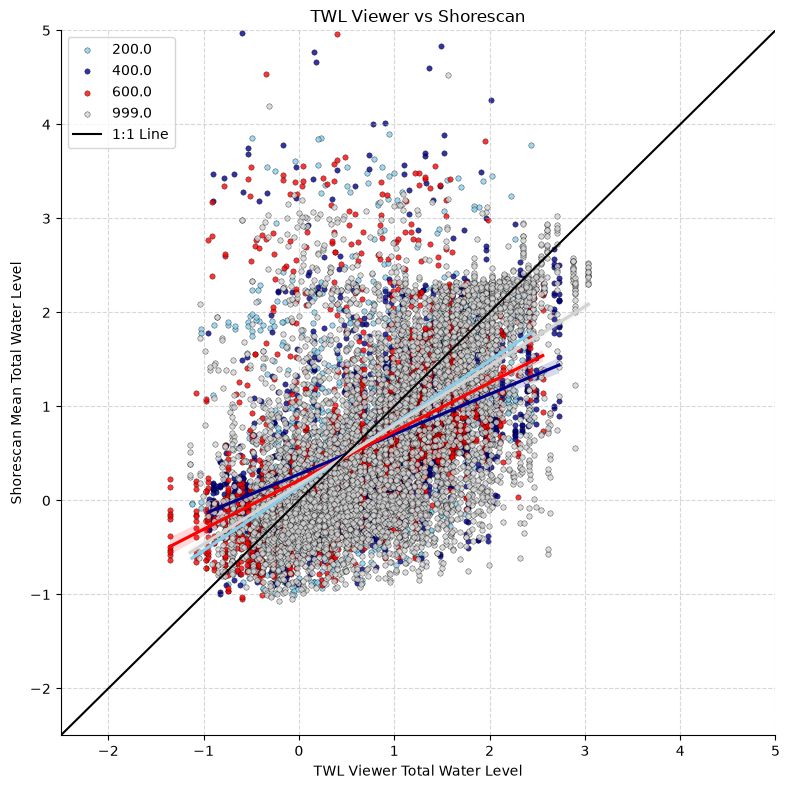

In [148]:
threshold_palette = {200: "skyblue", 400: "darkblue", 600: "red", 999: "lightgray"}
present_thresholds = sorted(df_ss["thresh"].unique())
print(present_thresholds)
palette = [threshold_palette[t] for t in present_thresholds if t in threshold_palette]

g = sns.lmplot(
        data=df_ss,
        x="cc_twl",
        y="ss_twl_mean",
        height=8,
        legend=False,
        hue="thresh",
        palette=palette,
        scatter_kws = {
            "linewidths": 0.3,
            "s": 15,
            "alpha": 0.8,
            "edgecolor": 'k',
        }
    )

ax = g.ax
ax.set_xlim([-2.5,5])
ax.set_ylim([-2.5,5])
limits = [
    min(ax.get_xlim()[0], ax.get_ylim()[0]),
    max(ax.get_xlim()[1], ax.get_ylim()[1]),
]
ax.plot(limits, limits, color="black", linestyle="-", label="1:1 Line")

ax.set_xlabel("TWL Viewer Total Water Level")
ax.set_ylabel("Shorescan Mean Total Water Level")
ax.grid(True, linestyle="--", alpha=0.5)
plt.title(f"TWL Viewer vs Shorescan")
plt.tight_layout()
plt.legend()
plt.savefig(f"TWLvSS_thresholds.png")
plt.show()